# Integrating displacement into OPD: boundary conditions, the four integrators, and how to measure errors

Every method returns a displacement field $d = (d_y, d_x)$, which is the gradient of the phase $\varphi$
(OPD $= \frac{p^2}{z}\varphi$). Integrating it needs a rule for the image border. The package has four integrators
(`available_integrators()`; chosen with `integrator=` on any method, default `poisson_neumann`):

| Name | What happens at the border | Solver |
|---|---|---|
| `poisson_neumann` (default) | no assumption on the values (zero normal slope) | least-squares Poisson, direct (DCT) |
| `poisson_zero_boundary` | $\varphi = 0$ on the whole border | Poisson, conjugate gradients (2500 it.); original Deep CWFS solver |
| `fourier_mirror` | gradients mirror-padded by N/2 on every side, **signs kept** | FFT, then crop |
| `fourier_asdi` | gradients extended anti-symmetrically (the derivative of a mirrored phase) | FFT on (2H, 2W), then crop |

Sections: 1. synthetic phases with known truth, 2. why mirror padding loses tilts and ASDI does not,
3. a real pair, 4. how to remove the bias before an RMSE.

In [1]:
import os
import time

import matplotlib.pyplot as plt
import numpy as np

from speckle_opd_retrieval import Setup, available_integrators, get_method, integrate, load_image

DATA = os.environ.get("SPECKLE_OPD_DATA", os.path.join("..", "..", "data"))
SAMPLES = os.path.join(DATA, "2026-04-13_cwfs_speckle_pairs_10_samples")
INTEGRATORS = list(available_integrators())
available_integrators()

{'poisson_neumann': 'least-squares Poisson solve, Neumann boundaries (DCT): exact and fast (default)',
 'poisson_zero_boundary': 'Poisson solve with OPD = 0 on the border (conjugate gradients): original Deep CWFS solver',
 'fourier_mirror': 'Fourier integration, gradients mirror-padded by N/2 (signs kept): loses tilts',
 'fourier_asdi': 'Fourier integration, anti-symmetric derivative extension (ASDI): no boundary artefacts'}

In [2]:
def bump(H, W, cy, cx, width, amp, tilt=0.0):
    """Gaussian phase bump [px²] at (cy, cx) plus ``tilt``·x, and its exact gradients at the pixel centres."""
    y, x = np.mgrid[0:H, 0:W].astype(float)
    phi = amp * np.exp(-(((y - cy) / width) ** 2 + ((x - cx) / width) ** 2))
    gy = phi * -2 * (y - cy) / width ** 2
    gx = phi * -2 * (x - cx) / width ** 2 + tilt
    phi = phi + tilt * x
    return phi - phi.mean(), gy, gx


def forward_gradients(phi):
    """Forward differences (last row / column 0): the sampling the two Poisson solvers assume."""
    gy = np.zeros_like(phi)
    gx = np.zeros_like(phi)
    gy[:-1] = np.diff(phi, axis=0)
    gx[:, :-1] = np.diff(phi, axis=1)
    return gy, gx


def relative_rms(error, truth):
    """RMS of the error divided by the RMS of the (mean-free) truth."""
    return np.sqrt(np.mean(error ** 2)) / np.sqrt(np.mean((truth - truth.mean()) ** 2))


def show(ax, img, title, cmap="gray", symmetric=False, vmin=None, vmax=None, label="px²"):
    """imshow with a colour bar; ``symmetric`` centres a diverging colour map on 0."""
    if symmetric:
        vmax = np.abs(img).max()
        vmin = -vmax
    im = ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
    plt.colorbar(im, ax=ax, shrink=0.8, label=label)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

## 1. Synthetic phases with known truth

- **A** object in the centre on a flat background (phase ≈ 0 at the border: the case zero boundary assumes),
- **B** object cut by the border,
- **C** centred object plus a tilt (wedge, tilted slide, global speckle drift).

The gradients are the exact derivatives at the pixel centres (**point samples**), as DIC and the networks deliver
them. The second table uses **forward differences** instead, the sampling the Poisson solvers are built for.

In [3]:
H, W = 256, 256
cases = {
    "A: object in the centre": bump(H, W, 128, 128, 30, 40),
    "B: object cut by the border": bump(H, W, 128, 230, 40, 40),
    "C: centred object + tilt": bump(H, W, 128, 128, 30, 40, tilt=0.05),
}

results = {}
for sampling in ["point samples", "forward differences"]:
    print(f"relative RMS error, gradients as {sampling}")
    print(f"  {'':30s}" + "".join(f"{name:>24s}" for name in INTEGRATORS))
    for case, (phi, gy, gx) in cases.items():
        if sampling == "forward differences":
            gy, gx = forward_gradients(phi)
        estimates = {name: integrate(np.stack([gy, gx]), name, device="cpu") for name in INTEGRATORS}
        if sampling == "point samples":
            results[case] = (phi, estimates)
        print(f"  {case:30s}" + "".join(f"{relative_rms(estimates[n] - phi, phi):24.1e}" for n in INTEGRATORS))

print("runtime for a 256 × 256 field (CPU):")
for name in INTEGRATORS:
    t0 = time.perf_counter()
    integrate(np.stack(cases["A: object in the centre"][1:]), name, device="cpu")
    print(f"  {name:22s} {time.perf_counter() - t0:.3f} s")

relative RMS error, gradients as point samples
                                         poisson_neumann   poisson_zero_boundary          fourier_mirror            fourier_asdi


  A: object in the centre                        2.0e-02                 1.9e-02                 7.7e-02                 1.8e-10


  B: object cut by the border                    1.5e-02                 4.9e-01                 1.4e-01                 5.0e-04


  C: centred object + tilt                       1.6e-02                 5.5e-01                 5.5e-01                 9.9e-05
relative RMS error, gradients as forward differences
                                         poisson_neumann   poisson_zero_boundary          fourier_mirror            fourier_asdi


  A: object in the centre                        1.6e-13                 3.9e-02                 7.9e-02                 2.0e-02


  B: object cut by the border                    4.6e-13                 5.0e-01                 1.4e-01                 1.5e-02


  C: centred object + tilt                       5.5e-13                 5.5e-01                 5.5e-01                 1.6e-02
runtime for a 256 × 256 field (CPU):
  poisson_neumann        0.006 s


  poisson_zero_boundary  34.000 s
  fourier_mirror         0.005 s
  fourier_asdi           0.007 s


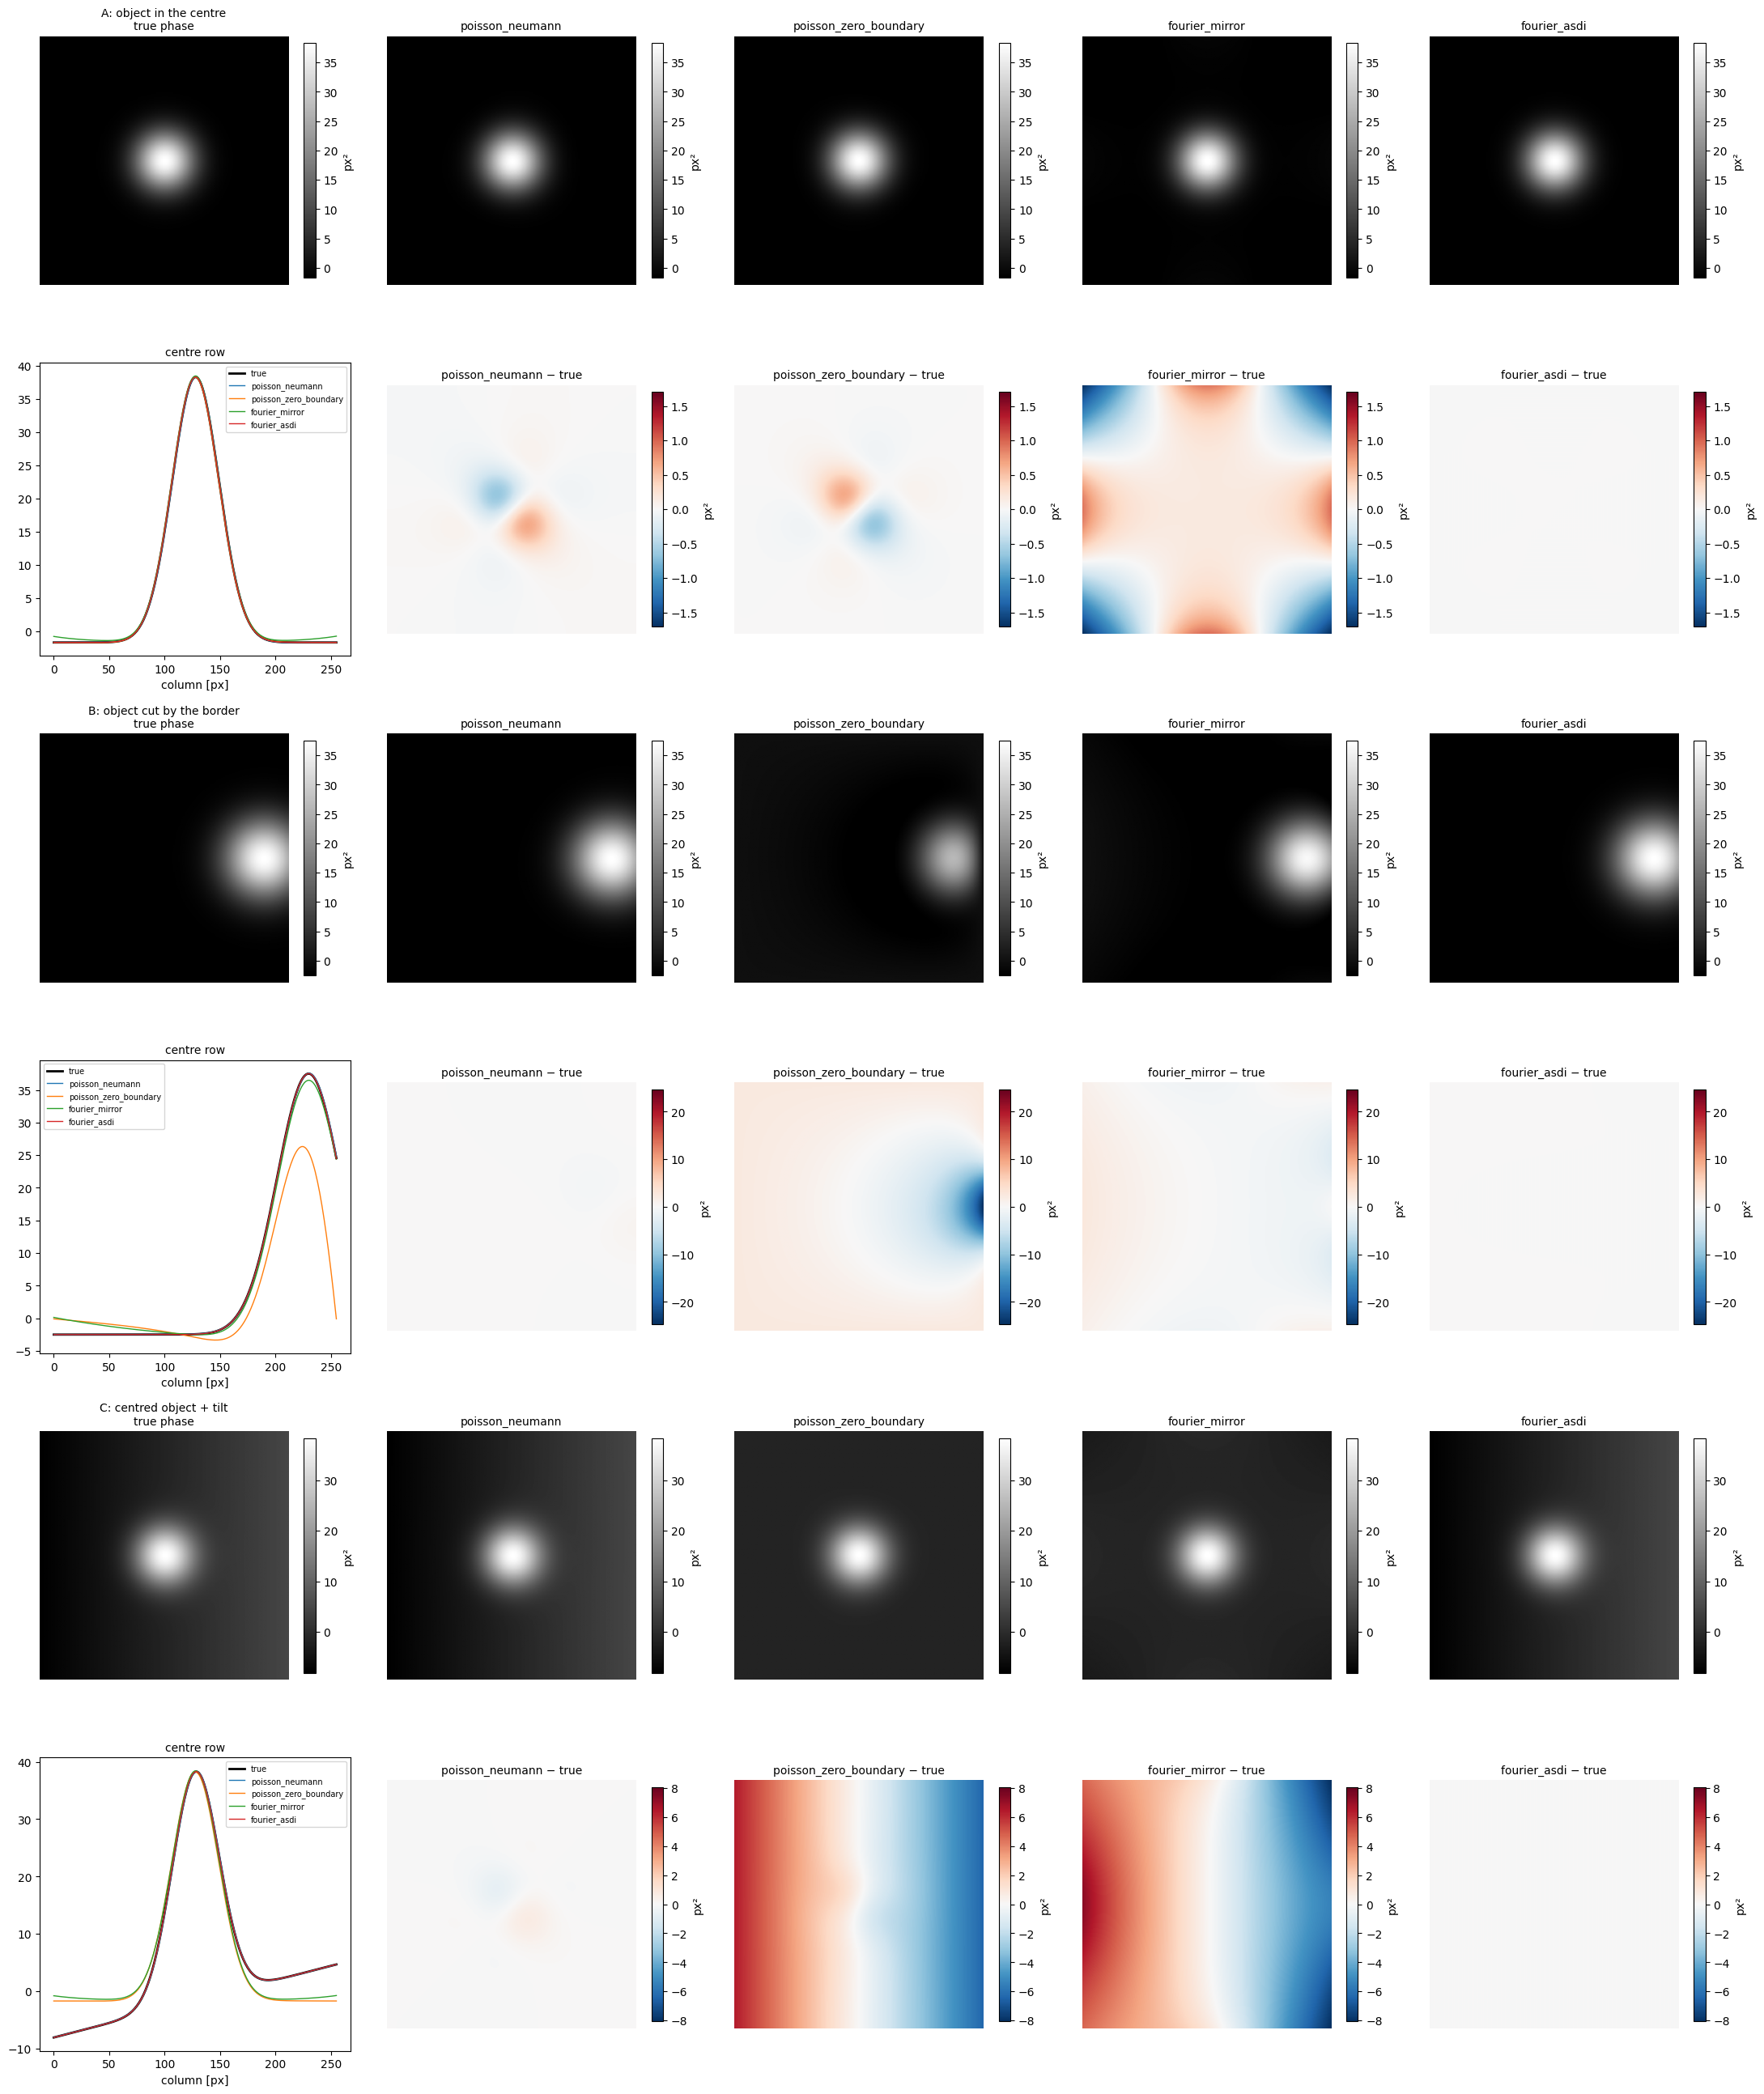

In [4]:
fig, axs = plt.subplots(6, 5, figsize=(22, 26))
for case_index, (case, (phi, estimates)) in enumerate(results.items()):
    top, bottom = axs[2 * case_index], axs[2 * case_index + 1]
    error_limit = max(np.abs(e - phi).max() for e in estimates.values())
    show(top[0], phi, f"{case}\ntrue phase", vmin=phi.min(), vmax=phi.max())
    bottom[0].plot(phi[128], "k", lw=2, label="true")
    for column, name in enumerate(INTEGRATORS, start=1):
        show(top[column], estimates[name], name, vmin=phi.min(), vmax=phi.max())
        show(bottom[column], estimates[name] - phi, f"{name} − true", "RdBu_r", vmin=-error_limit, vmax=error_limit)
        bottom[0].plot(estimates[name][128], lw=1, label=name)
    bottom[0].set_title("centre row", fontsize=10)
    bottom[0].set_xlabel("column [px]")
    bottom[0].legend(fontsize=7)
plt.tight_layout()

**Result (point samples).**
- `fourier_asdi` is the most accurate in all three cases (≤ 5e-4): it matches point-sampled gradients and has no
  boundary artefacts.
- `poisson_neumann` (default) is good in all three cases (1.5–2 %). Its remaining error is a ~half-pixel shift and
  smoothing, because its discrete Laplacian assumes forward differences; with forward differences (second table)
  it is exact (1e-13).
- `poisson_zero_boundary` is fine only for **A**; it pulls the cut object in **B** down to 0 at the border (50 %) and
  turns the tilt in **C** into a large error (55 %).
- `fourier_mirror` loses the tilt in **C** (55 %) and distorts **B** (14 %), see section 2.

## 2. Why mirror padding loses tilts and ASDI does not

Mirroring the *phase* across the right border, $\varphi(W - 1 + s) = \varphi(W - s)$, reverses the direction of
$x$, so the mirrored **x-gradient changes sign** ($\partial_x$ of a mirrored phase is $-\partial_x\varphi$); the
y-gradient keeps its sign. ASDI builds the extended gradients exactly like this, so they are the gradients of a
periodic, continuous phase. `fourier_mirror` copies the gradient images without the sign change: for a tilt
($g_x$ = constant) the padded $g_x$ is constant everywhere, its mean goes to the zero frequency, which carries no
phase, and the tilt is lost. (Mirroring the phase by N/2 **with** the sign change is the same periodic field as ASDI,
shifted by N/2, so it gives the same result.)

mean x-gradient: input +0.0500, mirror-padded +0.0500, ASDI -0.0000
The FFT drops the mean. Mirror padding keeps it in the mean, so it is lost; in ASDI the mean is 0 and the
tilt is carried by the sign changes (a triangle wave), so it survives.


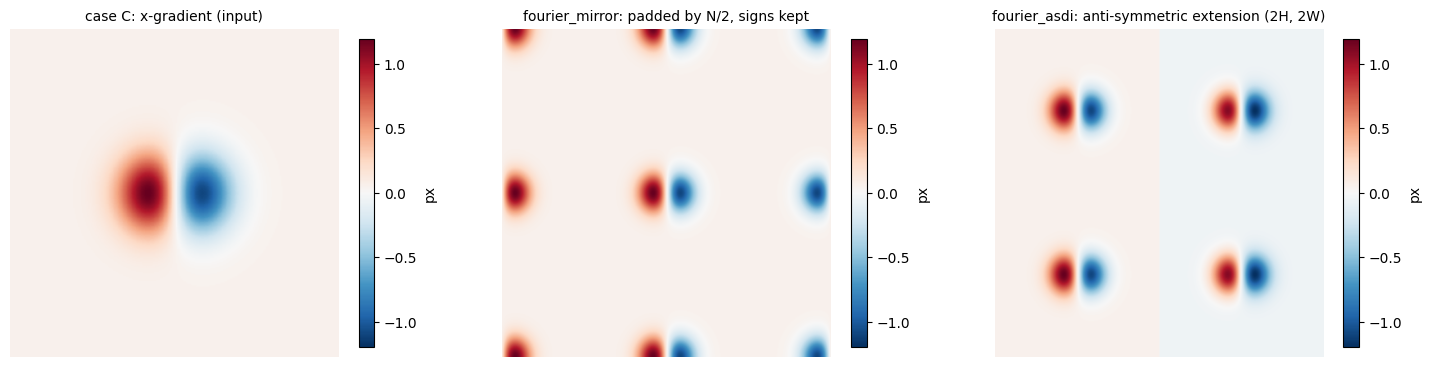

In [5]:
import torch

from speckle_opd_retrieval.core.poisson_integration_gradient_to_opd import mirror_pad

phi, gy, gx = cases["C: centred object + tilt"]
gx_t = np.asarray(gx)
mirror = mirror_pad(torch.tensor(gx_t), H // 2, W // 2).numpy()
asdi = np.block([[gx_t, -gx_t[:, ::-1]], [gx_t[::-1], -gx_t[::-1, ::-1]]])
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
show(axs[0], gx_t, "case C: x-gradient (input)", "RdBu_r", symmetric=True, label="px")
show(axs[1], mirror, "fourier_mirror: padded by N/2, signs kept", "RdBu_r", symmetric=True, label="px")
show(axs[2], asdi, "fourier_asdi: anti-symmetric extension (2H, 2W)", "RdBu_r", symmetric=True, label="px")
print(f"mean x-gradient: input {gx_t.mean():+.4f}, mirror-padded {mirror.mean():+.4f}, ASDI {asdi.mean():+.4f}")
print("The FFT drops the mean. Mirror padding keeps it in the mean, so it is lost; in ASDI the mean is 0 and the")
print("tilt is carried by the sign changes (a triangle wave), so it survives.")

## 3. Real pair: DIC displacement of sample pair 0

The object lies in the middle on a flat background (like case A), so all integrators should nearly agree.

poisson_neumann          0.17 s, max |difference to poisson_neumann| 0.0000 µm (OPD range 0.155 µm)


poisson_zero_boundary   85.69 s, max |difference to poisson_neumann| 0.0049 µm (OPD range 0.155 µm)


fourier_mirror           0.24 s, max |difference to poisson_neumann| 0.0046 µm (OPD range 0.155 µm)


fourier_asdi             0.26 s, max |difference to poisson_neumann| 0.0024 µm (OPD range 0.155 µm)


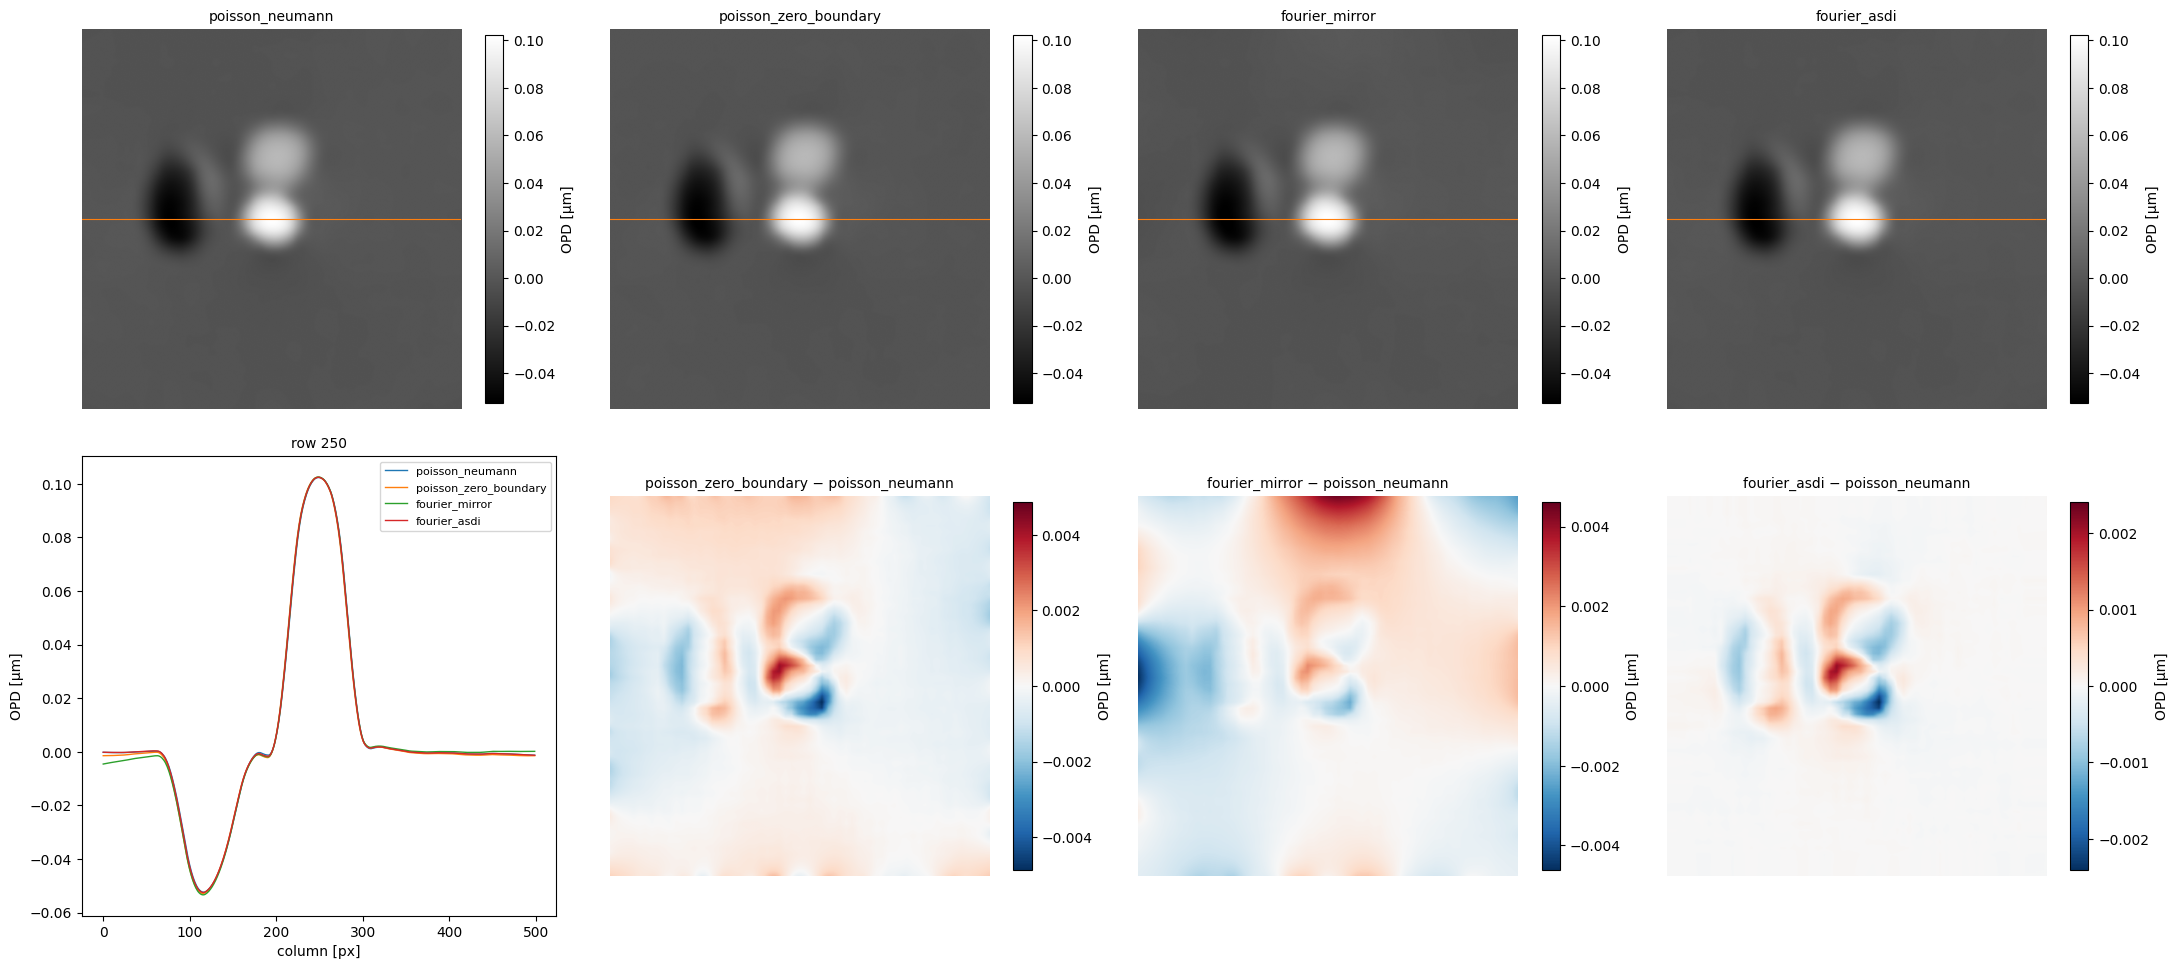

In [6]:
ref = load_image(os.path.join(SAMPLES, "reference", "0.tiff"))
spec = load_image(os.path.join(SAMPLES, "specimen", "0.tiff"))
setup = Setup(3.45e-6, 2.48e-3)
d = get_method("dic", setup, saturation=float(ref.max()), device="cpu").retrieve(ref, spec).displacement

real = {}
for name in INTEGRATORS:
    t0 = time.perf_counter()
    real[name] = setup.opd_scale * integrate(d, name, device="cpu") * 1e6   # µm
    print(f"{name:22s} {time.perf_counter() - t0:6.2f} s, max |difference to poisson_neumann| "
          f"{np.abs(real[name] - real['poisson_neumann']).max():.4f} µm (OPD range {np.ptp(real['poisson_neumann']):.3f} µm)")

row = ref.shape[0] // 2
fig, axs = plt.subplots(2, 4, figsize=(22, 10))
lo, hi = real["poisson_neumann"].min(), real["poisson_neumann"].max()
for column, name in enumerate(INTEGRATORS):
    show(axs[0, column], real[name], name, vmin=lo, vmax=hi, label="OPD [µm]")
    axs[0, column].axhline(row, color="tab:orange", lw=0.8)
for column, name in enumerate(INTEGRATORS[1:], start=1):
    show(axs[1, column], real[name] - real["poisson_neumann"], f"{name} − poisson_neumann", "RdBu_r",
         symmetric=True, label="OPD [µm]")
for name in INTEGRATORS:
    axs[1, 0].plot(real[name][row], lw=1, label=name)
axs[1, 0].set_title(f"row {row}", fontsize=10)
axs[1, 0].set_xlabel("column [px]")
axs[1, 0].set_ylabel("OPD [µm]")
axs[1, 0].legend(fontsize=8)
plt.tight_layout()

## 4. Removing the bias before an RMSE

Two kinds of bias can make an RMSE large although the shape is right.

1. **Piston (a constant).** Integration fixes $\varphi$ only up to a constant, for every integrator.
   The package returns mean-free OPD. Before an RMSE, remove the mean of the estimate *and* of the truth
   (or the mean over a background region, if the field of view is not representative).
2. **Tip/tilt (a plane).** A constant error in the displacement (global speckle drift, a slightly moved mask,
   a tilted slide) integrates to a ramp. `poisson_neumann` and `fourier_asdi` keep it (it is in the data);
   `poisson_zero_boundary` and `fourier_mirror` hide it, but distort the rest (cases B, C).
   Wavefront metrology therefore usually reports the **RMS error with piston and tip/tilt removed**:
   fit a plane $a + b\,y + c\,x$ to the error (estimate − truth) by least squares, subtract it, then take the RMS.
   Optionally ignore a border margin of a few pixels.

**On the gradients?** Yes, that is also common, and it answers a different question:
- **gradient (displacement) error** $\sqrt{\langle |d_\text{est} - d_\text{true}|^2\rangle}$, the *endpoint error*
  of optical flow, evaluates the displacement estimator (DIC, the network) on its own. It is independent of the
  integrator and of piston. A constant gradient bias is the tilt; remove the mean of each component of the error to
  get the tilt-free gradient error.
- **phase / OPD error** (piston + tilt removed) evaluates the whole pipeline including integration, in physical units.

For SynthEllips the ground truth is a gradient (`gt_gradients`, labels = −d), so the gradient error is the direct
comparison; for an OPD error, integrate the ground-truth gradients with the *same* integrator.

Demonstration: case A with a constant displacement bias (0.03 px in y, −0.05 px in x) and noise (σ = 0.02 px).

In [7]:
def remove_plane(img, margin=0):
    """Subtract the least-squares plane a + b·y + c·x (piston and tip/tilt), fitted inside ``margin``."""
    H, W = img.shape
    y, x = np.mgrid[0:H, 0:W].astype(float)
    inside = (slice(margin, H - margin), slice(margin, W - margin))
    basis = np.stack([np.ones(H * W), y.ravel(), x.ravel()], axis=1)
    coefficients, *_ = np.linalg.lstsq(basis.reshape(H, W, 3)[inside].reshape(-1, 3), img[inside].ravel(), rcond=None)
    return img - (basis @ coefficients).reshape(H, W)


def rms(img, margin=0):
    """Root mean square, ignoring ``margin`` pixels at the border."""
    H, W = img.shape
    return np.sqrt(np.mean(img[margin:H - margin, margin:W - margin] ** 2))


rng = np.random.default_rng(0)
phi, true_gy, true_gx = cases["A: object in the centre"]
est_gy = true_gy + 0.03 + 0.02 * rng.standard_normal(phi.shape)
est_gx = true_gx - 0.05 + 0.02 * rng.standard_normal(phi.shape)

print("gradient (displacement) error [px]")
error_y, error_x = est_gy - true_gy, est_gx - true_gx
print(f"  raw:                   {np.sqrt(np.mean(error_y ** 2 + error_x ** 2)):.4f}")
print(f"  mean gradient removed: {np.sqrt(np.mean((error_y - error_y.mean()) ** 2 + (error_x - error_x.mean()) ** 2)):.4f}"
      "   (= noise 0.02·√2 = 0.028)")

margin = 8
print("phase error [px²], RMS of (estimate − truth)")
print(f"  {'':22s}{'piston removed':>16s}{'+ tilt removed':>16s}{f'+ {margin} px margin':>18s}")
for name in INTEGRATORS:
    error = integrate(np.stack([est_gy, est_gx]), name, device="cpu") - phi
    print(f"  {name:22s}{rms(error - error.mean()):16.3f}{rms(remove_plane(error)):16.3f}"
          f"{rms(remove_plane(error, margin), margin):18.3f}")

gradient (displacement) error [px]
  raw:                   0.0649
  mean gradient removed: 0.0283   (= noise 0.02·√2 = 0.028)
phase error [px²], RMS of (estimate − truth)
                          piston removed  + tilt removed     + 8 px margin


  poisson_neumann                  4.312           0.110             0.116


  poisson_zero_boundary            0.112           0.111             0.117
  fourier_mirror                   0.432           0.432             0.345


  fourier_asdi                     4.315           0.019             0.018


**Reading the numbers.**
- With only piston removed, `poisson_neumann` and `fourier_asdi` show a large error (4.3 px²): the gradient bias
  became a ramp, as it should, since the bias is in the data.
- After removing piston + tilt, `fourier_asdi` drops to the noise level (0.019 px²). `poisson_neumann` drops to 0.11 px²,
  its own discretisation error for point-sampled gradients (the ~2 % of section 1), not noise.
- `poisson_zero_boundary` and `fourier_mirror` look better with only piston removed because they suppressed the ramp.
  That is misleading: here the object is centred (case A), so zero boundary happens to match Neumann after plane
  removal (0.11), while mirror padding stays worse (0.43). For objects touching the border (case B), both are far off.

**Recommendation for evaluations:** report the gradient error (mean removed) for the displacement estimator, and the
OPD RMSE with piston and tip/tilt removed (plane fitted to the error, optional border margin) for the full pipeline.